# Student Performance Prediction System Using Machine Learning

An end-to-end machine learning project to analyze student academic factors, predict examination scores, and classify pass/fail outcomes.

| | |
|---|---|
| **Domain** | Education / Machine Learning |
| **Tools** | Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, Streamlit |
| **Dataset** | Student Performance Factors Dataset (6,607 rows × 20 columns) |
| **Target Variables** | Exam_Score (Regression) and Result (Classification) |
| **Algorithms** | Linear Regression, Logistic Regression |
| **Input Features** | Study Hours, Attendance, Previous Scores |
| **Evaluation Metrics** | MAE, MSE, RMSE, R² Score, Accuracy, Precision, Recall, F1-Score |
| **Deliverables** | Jupyter Notebook, trained ML models, interactive Streamlit application, project documentation and exported visualizations |

## 1. Business Problem

Educational institutions often face challenges in identifying students who may struggle academically before their final examinations. Student performance is influenced by several factors, including study hours, attendance, previous academic scores, parental involvement, sleep habits and access to learning resources.

Traditional evaluation methods mainly depend on examination results and manual assessments, which may not provide sufficient insights into students' expected academic performance.

This project aims to develop a Machine Learning-based Student Performance Prediction System that analyzes various academic and behavioral factors to predict students' examination scores and pass/fail status.

The project uses Linear Regression to predict examination scores and Logistic Regression to classify students into pass or fail categories.

### Business Objectives
- Predict students' examination scores based on academic factors.
- Identify students who may be at risk of failing.
- Analyze the relationship between study hours, attendance and previous scores.
- Understand the factors influencing student academic performance.
- Support educators in identifying students who may require additional academic assistance.

## 2. Dataset Description
The project uses the Student Performance Factors dataset from Kaggle.

Dataset link: Download Student Performance Factors

The dataset contains approximately 6,607 student records and 20 columns.

Each row represents an individual student's academic and personal factors along with their examination score.

## 3. Technologies Used

| Library / Technology | Why it is used |
|---|---|
| Python | Core programming language |
| NumPy | Numerical computations and array operations |
| Pandas | Data loading, cleaning and manipulation |
| Matplotlib | Data visualization |
| Seaborn | Statistical visualization |
| Scikit-learn | Machine learning algorithms, preprocessing and model evaluation |
| Jupyter Notebook | Model development and experimentation |
| Streamlit | Interactive web application |
| Joblib | Saving and loading trained ML models |

### Step 1: Load and inspect your dataset

In [198]:
# 1. Importing Required Libraries

# In this section, we import the Python libraries required for data manipulation, numerical operations, visualization, and machine learning.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

##################################################################33

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

In [199]:
# 2. Loading the Dataset : We load the Student Performance Factors dataset using Pandas.
df = pd.read_csv(r"./datasets/stud_perf_factor.csv")
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [200]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [201]:
df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


In [202]:
# Shows rows and columns

print('Shape of dataset : ',df.shape)

Shape of dataset :  (6607, 20)


In [203]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [204]:
# Displays column names

print('Columns in a dataset : \n',df.columns.tolist())


Columns in a dataset : 
 ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [205]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [206]:
# Check duplicate records

df.duplicated().sum()

np.int64(0)

### Step 2: Data Cleaning and Preprocessing

In [207]:
# Checking Missing Values 
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [208]:
# checking missing values pecentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

Hours_Studied                 0.000000
Attendance                    0.000000
Parental_Involvement          0.000000
Access_to_Resources           0.000000
Extracurricular_Activities    0.000000
Sleep_Hours                   0.000000
Previous_Scores               0.000000
Motivation_Level              0.000000
Internet_Access               0.000000
Tutoring_Sessions             0.000000
Family_Income                 0.000000
Teacher_Quality               1.180566
School_Type                   0.000000
Peer_Influence                0.000000
Physical_Activity             0.000000
Learning_Disabilities         0.000000
Parental_Education_Level      1.362192
Distance_from_Home            1.014076
Gender                        0.000000
Exam_Score                    0.000000
dtype: float64

In [209]:
# Sepaerating numerical and  catgeorical columns 
numerical_columns = df.select_dtypes(include =['int64','float64']).columns
print('Numerical Columns : ',numerical_columns)


categorical_columns = df.select_dtypes(include=['object']).columns
print('\nCategorical Columns :',categorical_columns)

Numerical Columns :  Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='object')

Categorical Columns : Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')


### Handle missing numerical values

For numerical columns, we will use the median to fill missing values.

Why median?

Median is less affected by extremely high or low values compared with the mean.

In [210]:
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

### Handle missing categorical values
For categorical columns, we will use the mode (most frequently occurring value).

Why mode?

For example, if Teacher_Quality contains mostly "Medium", we can use "Medium" to fill missing entries in that column.

In [211]:
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [212]:
# check if are there any null

numerical_columns.isnull().sum()

np.int64(0)

In [213]:
categorical_columns.isnull().sum()

np.int64(0)

In [214]:
df.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [215]:
df.duplicated().sum()


# there are no duplicates in the dataset

np.int64(0)

In [216]:
print("Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

df.head()

Dataset Shape: (6607, 20)
Missing Values: 0
Duplicate Records: 0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [217]:
# Save your cleaned dataset

df.to_csv("./datasets/cleaned_student_performance.csv", index=False)

### Step 3: Exploratory Data Analysis (EDA)

In [218]:
df = pd.read_csv("./datasets/cleaned_student_performance.csv")
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [219]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [220]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [221]:
df.shape

(6607, 20)

In [222]:
df.isnull().sum().sum()

np.int64(0)

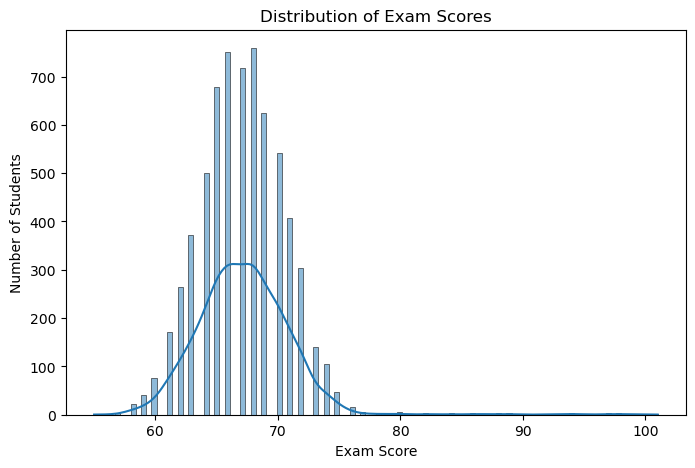

In [223]:
# Analyze the target variable — Exam Score

plt.figure(figsize=(8,5))

sns.histplot(df['Exam_Score'], kde=True)

plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')

plt.show()

In [224]:
print("Average Exam Score:", df['Exam_Score'].mean())
print("Minimum Exam Score:", df['Exam_Score'].min())
print("Maximum Exam Score:", df['Exam_Score'].max())

Average Exam Score: 67.23565914938702
Minimum Exam Score: 55
Maximum Exam Score: 101


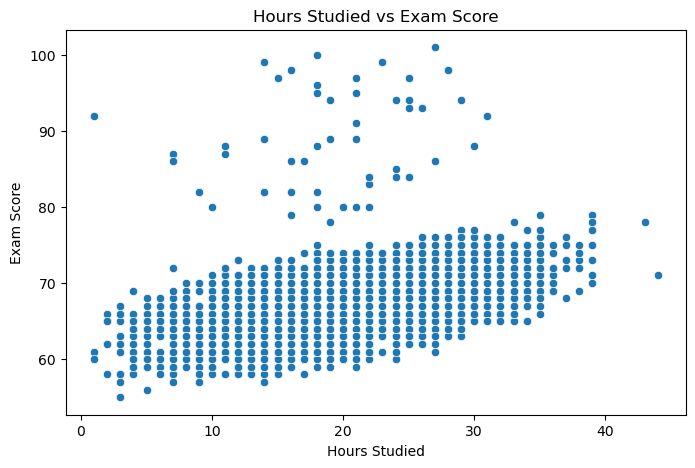

In [225]:
# Analyze Hours Studied vs Exam Score

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Hours_Studied',
    y='Exam_Score'
)

plt.title('Hours Studied vs Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

plt.show()

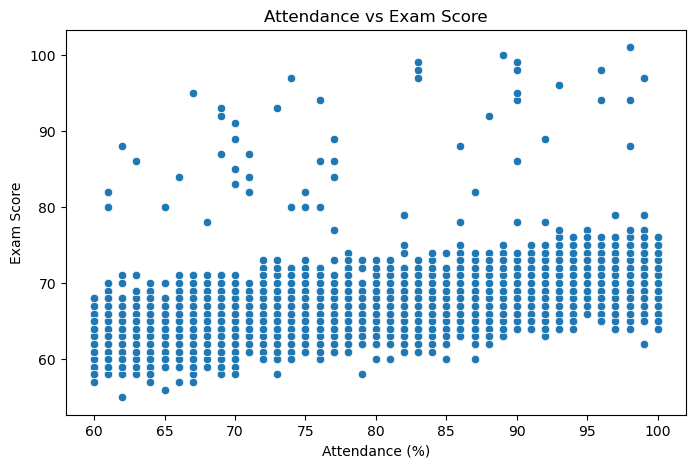

In [226]:
# Analyze Attendance vs Exam Score

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Attendance',
    y='Exam_Score'
)

plt.title('Attendance vs Exam Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Exam Score')

plt.show()

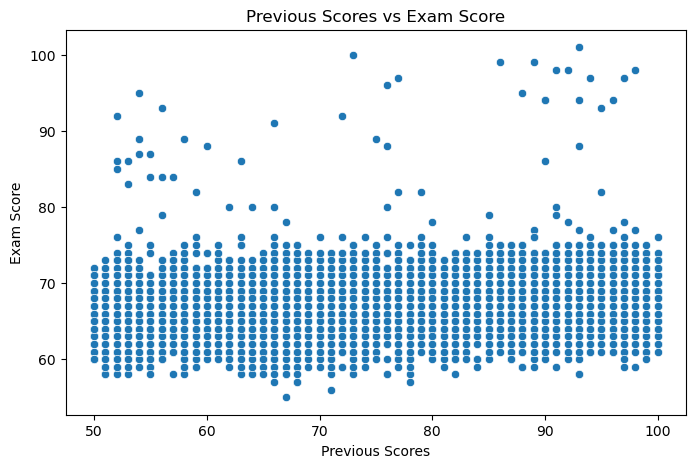

In [227]:
# Analyze Previous Scores vs Exam Score

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Previous_Scores',
    y='Exam_Score'
)

plt.title('Previous Scores vs Exam Score')
plt.xlabel('Previous Scores')
plt.ylabel('Exam Score')

plt.show()


In [228]:
# Now calcutae coreelations between numeical fetaures

correlation = df.select_dtypes(include=np.number).corr()

correlation['Exam_Score'].sort_values(ascending=False)

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64

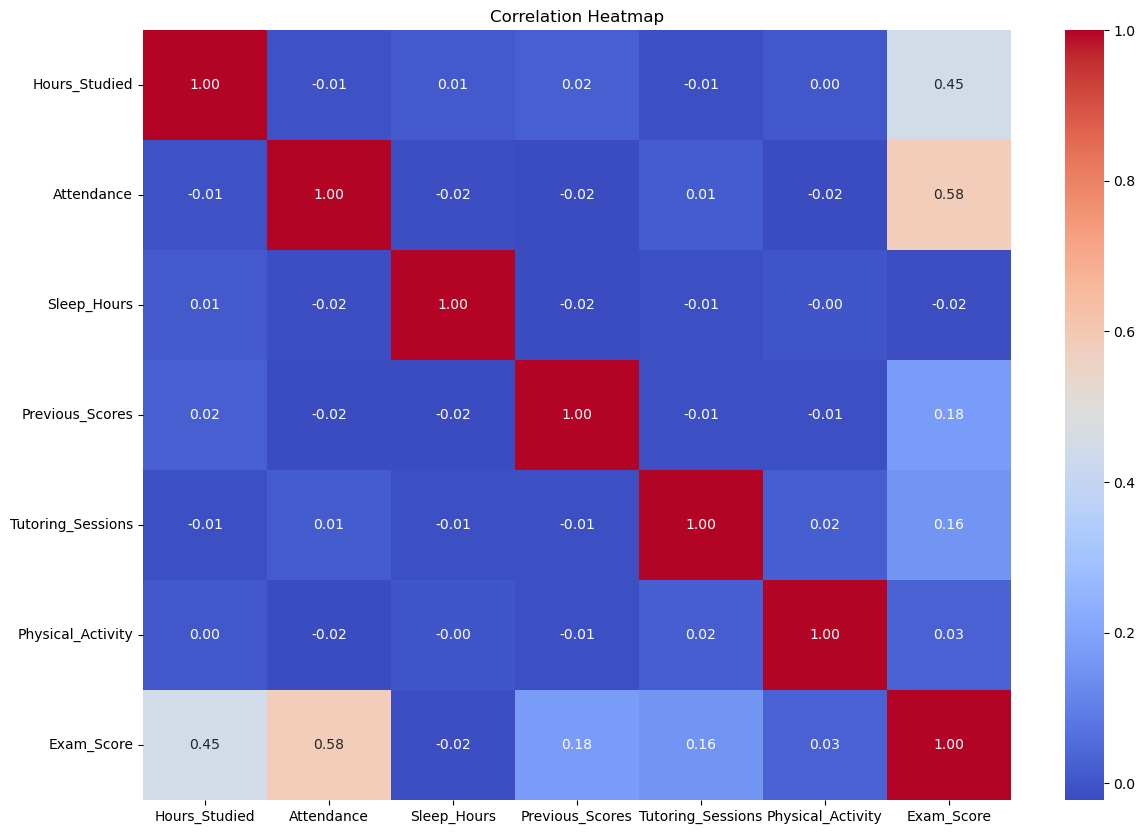

In [229]:
# Create a correlation heatmap

plt.figure(figsize=(14,10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

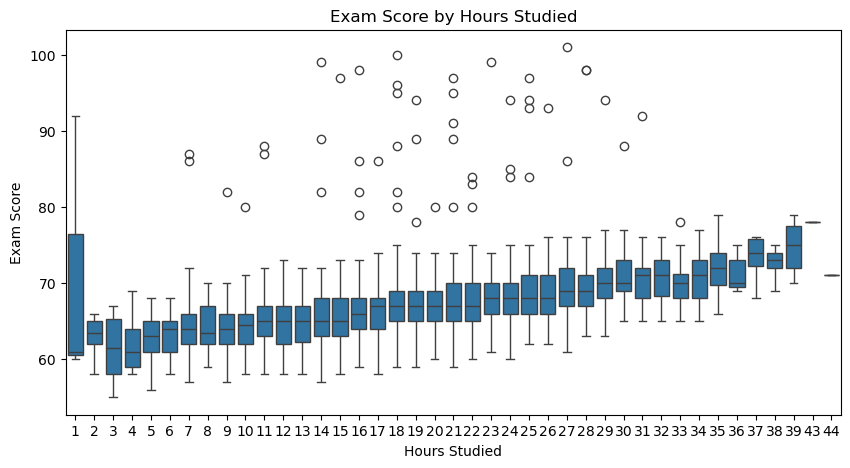

 This helps us see how exam scores vary across different study-hour levels. 


In [230]:
# Compare study hours using boxplot

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='Hours_Studied',
    y='Exam_Score'
)

plt.title('Exam Score by Hours Studied')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

plt.show()

print(" This helps us see how exam scores vary across different study-hour levels. ")

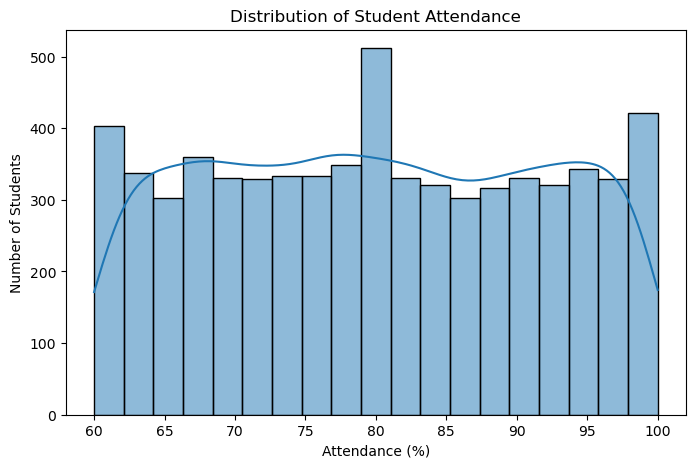

 This tells us whether most students have high, medium, or low attendance.


In [231]:
# Attendance Distribution
plt.figure(figsize=(8,5))

sns.histplot(df['Attendance'], kde=True)

plt.title('Distribution of Student Attendance')
plt.xlabel('Attendance (%)')
plt.ylabel('Number of Students')

plt.show()

print(" This tells us whether most students have high, medium, or low attendance.")

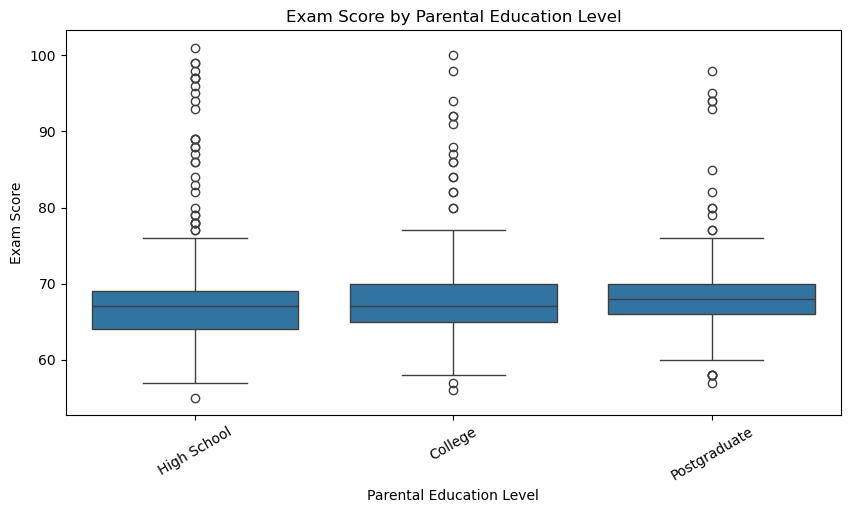

In [232]:
# ANAlyze Categorical Fetaures :

# Parental Education vs Exam Score

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='Parental_Education_Level',
    y='Exam_Score'
)

plt.title('Exam Score by Parental Education Level')
plt.xlabel('Parental Education Level')
plt.ylabel('Exam Score')

plt.xticks(rotation=30)

plt.show()

In [233]:
# Identify the important features
# Now let's look at the correlation with our target.

exam_correlation = (
    df.select_dtypes(include=np.number)
      .corr()['Exam_Score']
      .sort_values(ascending=False)
)

print(exam_correlation)

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


### EDA Summary

- Exam scores are concentrated around the mid-to-high range.
- Student study hours show a relationship with exam performance.
- Attendance is an important academic factor.
- Previous scores provide useful information about current academic performance.
- Numerical and categorical factors were explored using statistical summaries and visualizations.
- Correlation analysis was performed to understand relationships between numerical variables and exam scores.

## 5. Preparing Data for Machine Learning

In this step, the cleaned dataset is prepared for machine learning.
We separate the input features from the target variables and divide the data into training and testing sets.

In [234]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

### 5.1 Creating Performance Status

Since the dataset does not contain a Pass/Fail column, we create a project-defined classification target based on Exam_Score.

- Score below 65 → Needs Academic Support
- Score 65 or above → Satisfactory Performance

The original Exam_Score values are not modified.

In [235]:
df['Performance_Status'] = np.where(
    df['Exam_Score'] < 65,
    0,
    1
)

In [236]:
df['Performance_Status'].value_counts()

Performance_Status
1    5155
0    1452
Name: count, dtype: int64

In [237]:
df['Performance_Status'].value_counts(normalize=True) * 100

Performance_Status
1    78.023309
0    21.976691
Name: proportion, dtype: float64

In [238]:
# Select features for prediction

features = [
    'Hours_Studied',
    'Attendance',
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions',
    'Physical_Activity'
]

features

['Hours_Studied',
 'Attendance',
 'Sleep_Hours',
 'Previous_Scores',
 'Tutoring_Sessions',
 'Physical_Activity']

In [239]:
X = df[features]
X

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
0,23,84,7,73,0,3
1,19,64,8,59,2,4
2,24,98,7,91,2,4
3,29,89,8,98,1,4
4,19,92,6,65,3,4
...,...,...,...,...,...,...
6602,25,69,7,76,1,2
6603,23,76,8,81,3,2
6604,20,90,6,65,3,2
6605,10,86,6,91,2,3


In [240]:
# Create the Linear Regression target
y_reg=df['Exam_Score']
y_reg.head()

0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64

In [241]:
# Create the Logistic Regression target

y_clf = df['Performance_Status']

## Split the data for LINEAR REGRESSION

In [242]:
X_train_reg, X_test_reg ,y_train_reg, y_test_reg = train_test_split(
    X,
    y_reg,
    test_size=0.20,
    random_state=42
        
)

In [243]:
print("Training Data :",X_train_reg.shape)
print("Testing Data :",X_test_reg.shape)

Training Data : (5285, 6)
Testing Data : (1322, 6)


## Split the data for LOGISTIC REGRESSION

In [244]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X,
    y_clf,
    random_state=42,
    test_size=0.20,
    stratify=y_clf
)

In [245]:
print("Classification Training:", X_train_clf.shape)
print("Classification Testing:", X_test_clf.shape)

Classification Training: (5285, 6)
Classification Testing: (1322, 6)


In [246]:
print("Training class distribution:")
print(y_train_clf.value_counts())

print("\nTesting class distribution:")
print(y_test_clf.value_counts())

Training class distribution:
Performance_Status
1    4124
0    1161
Name: count, dtype: int64

Testing class distribution:
Performance_Status
1    1031
0     291
Name: count, dtype: int64


In [247]:
print("Features:")
print(features)

print("\nRegression Target:")
print("Exam_Score")

print("\nClassification Target:")
print("Performance_Status")

print("\nTraining samples:", len(X_train_reg))
print("Testing samples:", len(X_test_reg))

Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Regression Target:
Exam_Score

Classification Target:
Performance_Status

Training samples: 5285
Testing samples: 1322


# LINEAR REGRESSION MODEL

In [248]:
linear_model = LinearRegression()
linear_model.fit(X_train_reg, y_train_reg)

LinearRegression()

In [249]:
y_pred_reg = linear_model.predict(X_test_reg)

In [250]:
# Compare acutal and predicted scores

comparison = pd.DataFrame({
    'Actual Score': y_test_reg.values,
    'Predicted Score': y_pred_reg
})

comparison

,Actual Score,Predicted Score
0,65,66.090430
1,65,67.255843
2,71,68.445187
3,64,66.765869
4,66,65.652394
...,...,...
1317,69,66.981914
1318,72,71.318974
1319,66,65.936940
1320,63,65.981514


In [251]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': linear_model.coef_
})

coefficients

,Feature,Coefficient
0,Hours_Studied,0.289269
1,Attendance,0.198667
2,Sleep_Hours,-0.033519
3,Previous_Scores,0.048211
4,Tutoring_Sessions,0.509866
5,Physical_Activity,0.151104


In [252]:
linear_model.intercept_

np.float64(40.97457017291117)

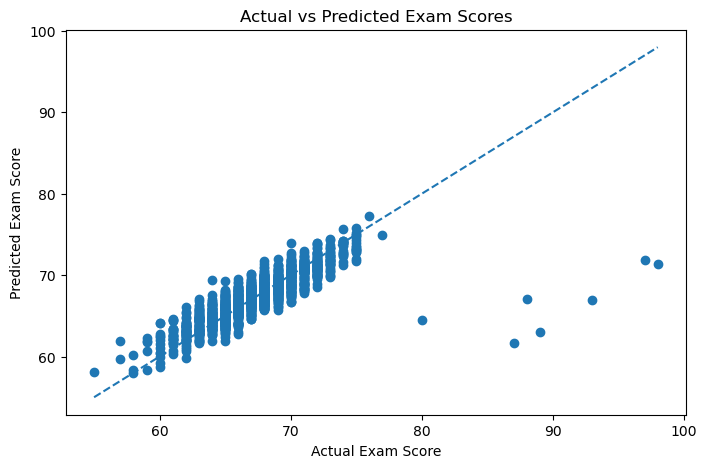

In [253]:
# Visualize Actual vs Predicted Scores

plt.figure(figsize=(8,5))

plt.scatter(y_test_reg, y_pred_reg)

plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)

plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Exam Scores')

plt.show()

In [254]:
comparison.to_csv(
    "./datasets/regression_predictions.csv",
    index=False
)

## Model Evaluation - Linear Regression

In [255]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 1.265855848186001


In [256]:
mse = mean_squared_error(y_test_reg, y_pred_reg)

print("Mean Squared Error:", mse)

Mean Squared Error: 5.0654567775480785


In [257]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 2.250656965765347


In [258]:
r2 = r2_score(y_test_reg, y_pred_reg)

print("R2 Score:", r2)

R2 Score: 0.641639136466839


In [259]:
print("Linear Regression Model Evaluation")

print("-----------------------------------")

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Linear Regression Model Evaluation
-----------------------------------
MAE : 1.27
MSE : 5.07
RMSE: 2.25
R2 Score: 0.6416


In [260]:
evaluation_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Value': [mae, mse, rmse, r2]
})

evaluation_results

,Metric,Value
0,MAE,1.265856
1,MSE,5.065457
2,RMSE,2.250657
3,R2 Score,0.641639


### Linear Regression Model Evaluation - Conclusion

The Linear Regression model was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R2 Score.

These evaluation metrics help measure the difference between actual and predicted examination scores and determine how well the model explains student performance.

The model performance is analyzed to understand its prediction accuracy and identify opportunities for improvement.

## Logistic Regression Model

Logistic Regression is a supervised machine learning algorithm used for classification problems.

In this project, Logistic Regression is used to classify students into two academic performance categories:
- 0: Needs Academic Support
- 1: Satisfactory Performance

In [261]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_clf, y_train_clf)
y_pred_clf = logistic_model.predict(X_test_clf)

In [262]:
classification_comparison = pd.DataFrame({
    'Actual Status': y_test_clf.values,
    'Predicted Status': y_pred_clf
})

classification_comparison.head(10)

,Actual Status,Predicted Status
0,0,0
1,0,0
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [263]:
y_probability = logistic_model.predict_proba(X_test_clf)

In [264]:
# Check the model coefficients

logistic_coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': logistic_model.coef_[0]
})

logistic_coefficients

,Feature,Coefficient
0,Hours_Studied,0.361617
1,Attendance,0.251755
2,Sleep_Hours,0.021124
3,Previous_Scores,0.056894
4,Tutoring_Sessions,0.625696
5,Physical_Activity,0.313919


In [265]:
logistic_model.intercept_

array([-30.31978434])

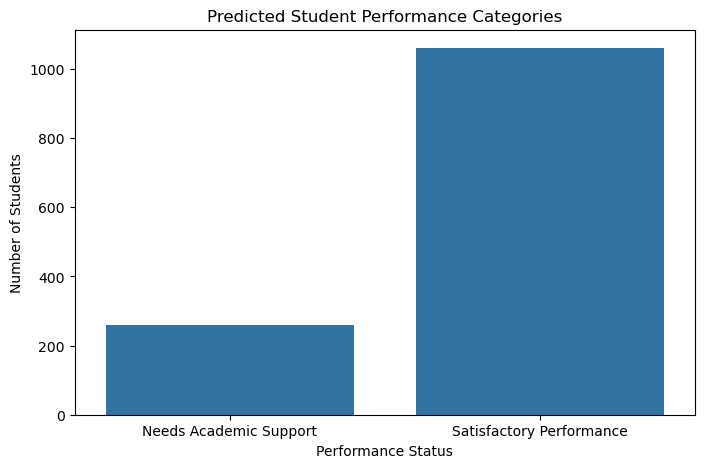

In [266]:
plt.figure(figsize=(8,5))

sns.countplot(
    x=y_pred_clf
)

plt.title('Predicted Student Performance Categories')
plt.xlabel('Performance Status')
plt.ylabel('Number of Students')

plt.xticks(
    [0, 1],
    ['Needs Academic Support', 'Satisfactory Performance']
)

plt.show()

In [267]:
classification_comparison.to_csv(
    "./datasets/classification_predictions.csv",
    index=False
)

# Model Evaluation - Logistic Regression

In [268]:
accuracy = accuracy_score(y_test_clf, y_pred_clf)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 88.35 %


In [269]:
precision = precision_score(
    y_test_clf,
    y_pred_clf,
)

print("Precision:", round(precision, 4))

Precision: 0.9133


In [270]:
recall = recall_score(
    y_test_clf,
    y_pred_clf,
)

print("Recall:", round(recall, 4))

Recall: 0.9399


In [271]:
f1 = f1_score(
    y_test_clf,
    y_pred_clf,
)

print("F1 Score:", round(f1, 4))

F1 Score: 0.9264


In [272]:
print("Logistic Regression Model Evaluation")
print("------------------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Logistic Regression Model Evaluation
------------------------------------
Accuracy : 0.8835
Precision: 0.9133
Recall   : 0.9399
F1 Score : 0.9264


In [273]:
print(classification_report(
    y_test_clf,
    y_pred_clf,
    labels=[0, 1],
    target_names=[
        'Needs Academic Support',
        'Satisfactory Performance'
    ],
    zero_division=0
))

                          precision    recall  f1-score   support

  Needs Academic Support       0.76      0.68      0.72       291
Satisfactory Performance       0.91      0.94      0.93      1031

                accuracy                           0.88      1322
               macro avg       0.84      0.81      0.82      1322
            weighted avg       0.88      0.88      0.88      1322



In [274]:
cm = confusion_matrix(
    y_test_clf,
    y_pred_clf,
    labels=[0, 1]
)

print(cm)

[[199  92]
 [ 62 969]]


In [275]:
classification_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision (Support)',
        'Recall (Support)',
        'F1 Score (Support)',
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        f1,
       ]
})

classification_results

,Metric,Value
0,Accuracy,0.883510
1,Precision (Support),0.913289
2,Recall (Support),0.939864
3,F1 Score (Support),0.926386


In [276]:
classification_results.to_csv(
    "./datasets/classification_evaluation.csv",
    index=False
)

### Logistic Regression Model Evaluation - Conclusion

The Logistic Regression model was evaluated using Accuracy, Precision, Recall, F1-score and Confusion Matrix

The model classifies students into two project-defined academic performance categories: Needs Academic Support and Satisfactory Performance.

The evaluation metrics help us understand the model's classification performance and identify areas for improvement.

The results can help demonstrate how machine learning can support the identification of students who may benefit from additional academic assistance.

In [277]:
# Saving the trained models 
os.makedirs("./models", exist_ok=True)

In [278]:
joblib.dump(
    linear_model,
    "./models/linear_regression_model.pkl"
)

['./models/linear_regression_model.pkl']

In [279]:
joblib.dump(
    logistic_model,
    "./models/logistic_regression_model.pkl"
)

['./models/logistic_regression_model.pkl']

In [280]:
print("Saved Models:")

print(os.listdir("./models"))

Saved Models:
['features.pkl', 'linear_regression_model.pkl', 'logistic_regression_model.pkl']


In [281]:
loaded_linear_model = joblib.load(
    "./models/linear_regression_model.pkl"
)

loaded_logistic_model = joblib.load(
    "./models/logistic_regression_model.pkl"
)

print("Linear Regression Model Loaded Successfully")
print("Logistic Regression Model Loaded Successfully")

Linear Regression Model Loaded Successfully
Logistic Regression Model Loaded Successfully


In [282]:
os.makedirs("./models", exist_ok=True)

joblib.dump(linear_model, "./models/linear_regression_model.pkl")
joblib.dump(logistic_model, "./models/logistic_regression_model.pkl")

joblib.dump(features, "./models/features.pkl")

print("Models saved successfully!")
print(os.listdir("./models"))

Models saved successfully!
['features.pkl', 'linear_regression_model.pkl', 'logistic_regression_model.pkl']
